# Fuel Price Predictor: Parramatta U91
**MMA3001 individual project.** Goal: forecast the Parramatta unleaded 91 price 2–3 days ahead.

### Part 1: Load and clean the supporting data
Before the FuelCheck prices arrive, we prepare the four things that drive pump prices:

| Data | Source | Why it matters |
|---|---|---|
| Terminal gate price (TGP) | Australian Institute of Petroleum | The **wholesale** price service stations pay. Pump price = TGP + retail margin |
| AUD/USD exchange rate | Reserve Bank of Australia | Oil is bought in US dollars. A weaker AUD makes fuel dearer |
| Brent crude oil | FRED (US Federal Reserve) | The raw material. Oil price changes flow into the TGP, then the pump |
| Fuel excise | ATO | A fixed tax per litre, changed every February and August, plus the 2022 and 2026 cuts |

**Plan for each dataset:** load → look at it → keep only the columns we need → fix types → check for missing values and duplicates → cut to our date range → plot to sanity-check.

Then we **merge everything into one table with one row per day**.

## 1. Setup

In [1]:
import pandas as pd               # tables
import numpy as np                # maths
import matplotlib.pyplot as plt   # plots
import os

# All data files live in the "data" folder next to this notebook. Check Python can see them:
print(os.listdir("data"))

['fuelcheck', 'exchange_rate_2023-current.xls', 'README.md', 'AIP_Terminal_gate_prices_Data_09-Oct-2026.xlsx', 'exchange_rate_2018-2022.xls', 'DCOILBRENTEU.csv', 'exchange_rate_2014-2017.xls']


In [2]:
# Our study period. FuelCheck starts in August 2016; the files we have go to early October 2026.
# Defining the dates ONCE here means every dataset gets cut to exactly the same range.
START = "2016-08-01"
END   = "2026-10-09"

## 2. Terminal gate prices (TGP)
The AIP file has a **NOTES** sheet, a **Petrol TGP** sheet and a **Diesel TGP** sheet. We only need **petrol** (U91 is petrol), and only the **Sydney** column, because Parramatta is supplied from the Sydney terminals.

In [3]:
# sheet_name picks the sheet we want; the other sheets are ignored
terminal_prices = pd.read_excel("data/AIP_Terminal_gate_prices_Data_09-Oct-2026.xlsx", sheet_name="Petrol TGP")
print(terminal_prices.shape)
terminal_prices.head()

(5942, 9)


,AVERAGE ULP TGPS\n(inclusive of GST),Sydney,Melbourne,Brisbane,Adelaide,Perth,Darwin,Hobart,National\nAverage
0,2004-01-01,86.3,85.1,86.4,87.2,88.5,89.7,87.9,86.4
1,2004-01-02,86.3,85.1,86.4,87.2,88.5,89.7,87.9,86.4
2,2004-01-05,86.4,85.3,86.4,87.2,89.0,89.7,87.9,86.5
3,2004-01-06,86.8,85.6,87.0,87.7,89.1,90.3,88.5,86.9
4,2004-01-07,86.7,85.5,87.0,87.7,89.1,90.3,88.5,86.8


The first column has a long messy name (`AVERAGE ULP TGPS (inclusive of GST)`) and holds the dates. We only keep the date and Sydney columns, and rename them `date` and `terminal_price`.

**Naming tip:** use lowercase with underscores (`terminal_price`), not spaces (`Terminal Gate Prices`). Spaces work, but they're easy to mistype, and every later cell has to match the name *exactly*, including capitals. One consistent style avoids "KeyError" bugs.

In [4]:
terminal_prices = terminal_prices.iloc[:, [0, 1]]               # column 0 = date, column 1 = Sydney (iloc picks columns by position)
terminal_prices.columns = ["date", "terminal_price"]           # short, clear names
terminal_prices.head()

,date,terminal_price
0,2004-01-01,86.3
1,2004-01-02,86.3
2,2004-01-05,86.4
3,2004-01-06,86.8
4,2004-01-07,86.7


In [5]:
# Make sure the types are right: dates as real dates, prices as numbers.
# errors="coerce" turns anything that isn't a valid date/number (e.g. a stray note) into NaN, so we can find it.
terminal_prices["date"] = pd.to_datetime(terminal_prices["date"], errors="coerce")
terminal_prices["terminal_price"]  = pd.to_numeric(terminal_prices["terminal_price"], errors="coerce")
terminal_prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 5942 entries, 0 to 5941
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date            5942 non-null   datetime64[us]
 1   terminal_price  5942 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 93.0 KB


In [6]:
# Check for problems: missing values and duplicate dates
print("Missing values:\n", terminal_prices.isna().sum())
print("Duplicate dates:", terminal_prices["date"].duplicated().sum())

Missing values:
 date              0
terminal_price    0
dtype: int64
Duplicate dates: 0


In [7]:
# Keep only our study period
terminal_prices = terminal_prices[(terminal_prices["date"] >= START) & (terminal_prices["date"] <= END)]
print("Rows in study period:", len(terminal_prices))
terminal_prices.describe()

Rows in study period: 2660


,date,terminal_price
count,2660,2660.000000
mean,2021-09-04 12:00:00,145.466877
min,2016-08-01 00:00:00,81.400000
25%,2019-02-17 06:00:00,122.075000
50%,2021-09-04 12:00:00,142.100000
75%,2024-03-22 18:00:00,167.300000
max,2026-10-09 00:00:00,249.000000
std,NaN,29.225282


In [8]:
# AIP only publishes on business days, so weekends are missing. Count which weekdays appear (0 = Monday, 6 = Sunday):
terminal_prices["date"].dt.dayofweek.value_counts().sort_index()

date
0    532
1    532
2    532
3    532
4    532
Name: count, dtype: int64

Only Monday to Friday appear (0–4), so weekends are missing **by design**, not because of errors. We fill them in Step 6 when we build the daily table.

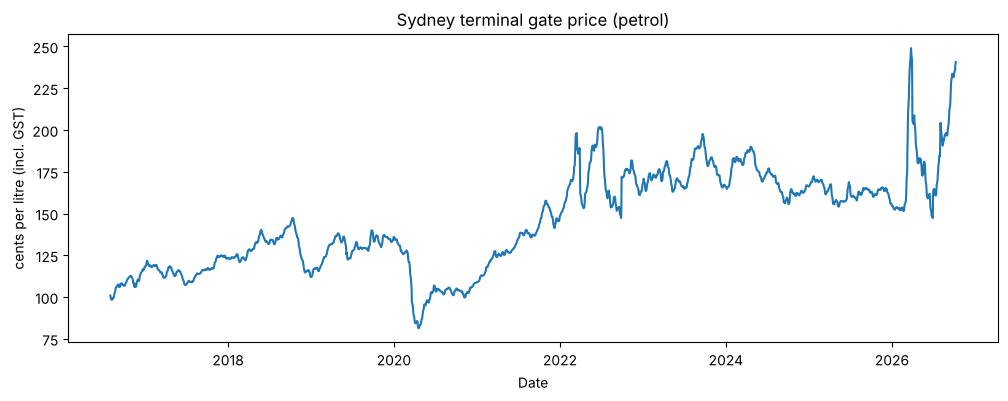

In [9]:
plt.figure(figsize=(12,4))
plt.plot(terminal_prices["date"], terminal_prices["terminal_price"])
plt.title("Sydney terminal gate price (petrol)")
plt.xlabel("Date"); plt.ylabel("cents per litre (incl. GST)")
plt.show()

**Sanity check:** the plot should show the 2020 COVID crash, the 2022 spike (Russia–Ukraine), the dip in mid-2022 when excise was halved, and a dip around April–July 2026 from the 2026 excise cut. Seeing known events in the right places tells us the data is loaded correctly.

## 3. AUD/USD exchange rate
The RBA splits the daily data into three files: 2014–2017, 2018–2022 and 2023–current. They have the same layout, so we load all three the same way and stack them on top of each other.

Each file has **11 rows of header information** (title, description, units, source …) before the data starts, so we skip those rows. The AUD/USD rate is in the second column (`A$1=USD`). The other 20+ columns are other currencies we don't need.

In [10]:
# Look at the top of one file first to see the layout
pd.read_excel("data/exchange_rate_2023-current.xls", header=None).iloc[:13, :3]

,0,1,2
0,F11.1 EXCHANGE RATES,NaN,NaN
1,Title,A$1=USD,Trade-weighted Index May 1970 = 100
2,Description,AUD/USD Exchange Rate; see notes for further d...,Australian Dollar Trade-weighted Index
3,Frequency,Daily,Daily
4,Type,Indicative,Indicative
5,Units,USD,Index
6,NaN,NaN,NaN
7,NaN,NaN,NaN
8,Source,WM/Reuters,RBA
9,Publication date,2026-10-09 00:00:00,2026-10-09 00:00:00


In [11]:
files = ["data/exchange_rate_2014-2017.xls", "data/exchange_rate_2018-2022.xls", "data/exchange_rate_2023-current.xls"]

parts = []
for f in files:
    # skiprows=11 jumps over the header block; usecols=[0, 1] keeps only the date and AUD/USD columns
    part = pd.read_excel(f, header=None, skiprows=11, usecols=[0, 1], names=["date", "audusd"])
    parts.append(part)

fx = pd.concat(parts, ignore_index=True)    # stack the three files into one table
print(fx.shape)
fx.head()

(3207, 2)


,date,audusd
0,2014-01-02,0.8912
1,2014-01-03,0.8982
2,2014-01-06,0.8949
3,2014-01-07,0.8920
4,2014-01-08,0.8931


In [12]:
fx["date"]   = pd.to_datetime(fx["date"], errors="coerce")
fx["audusd"] = pd.to_numeric(fx["audusd"], errors="coerce")

print("Missing values:\n", fx.isna().sum())
print("Duplicate dates:", fx["date"].duplicated().sum())   # would catch any overlap between the three files

Missing values:
 date      0
audusd    1
dtype: int64
Duplicate dates: 0


In [13]:
# Look at the missing value(s)
fx[fx["audusd"].isna()]

,date,audusd
349,2015-05-25,NaN


The one missing rate is on 25 May 2015, which is before our study period, so the date filter in the next cell removes it anyway. If a gap like this were inside our period we **wouldn't delete the day**. We'd give it the previous day's rate (forward fill, Step 6), which is a sensible guess because exchange rates move very little in a day.

In [14]:
fx = fx[(fx["date"] >= START) & (fx["date"] <= END)]
print("Rows in study period:", len(fx))
fx.describe()

Rows in study period: 2559


,date,audusd
count,2559,2559.000000
mean,2021-09-04 05:10:03.516998,0.704132
min,2016-08-02 00:00:00,0.557100
25%,2019-02-18 12:00:00,0.665900
50%,2021-09-02 00:00:00,0.702900
75%,2024-03-21 12:00:00,0.741750
max,2026-10-09 00:00:00,0.812100
std,NaN,0.046386


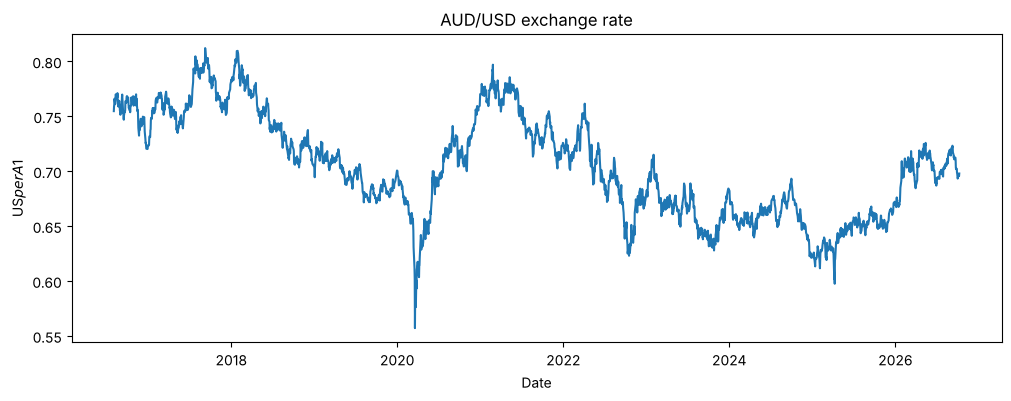

In [15]:
plt.figure(figsize=(12,4))
plt.plot(fx["date"], fx["audusd"])
plt.title("AUD/USD exchange rate")
plt.xlabel("Date"); plt.ylabel("US$ per A$1")
plt.show()

## 4. Brent crude oil price
FRED gives a simple CSV with two columns. Blank cells are days the London oil market was closed (Christmas, Easter, UK bank holidays).

In [16]:
brent = pd.read_csv("data/DCOILBRENTEU.csv")
brent.columns = ["date", "brent_usd"]      # rename the FRED code to something readable
brent["date"] = pd.to_datetime(brent["date"])
brent["brent_usd"] = pd.to_numeric(brent["brent_usd"], errors="coerce")

print(brent.shape)
print("Missing values:\n", brent.isna().sum())
print("Duplicate dates:", brent["date"].duplicated().sum())

(10275, 2)
Missing values:
 date            0
brent_usd    1173
dtype: int64
Duplicate dates: 0


In [17]:
brent = brent[(brent["date"] >= START) & (brent["date"] <= END)]
print("Rows in study period:", len(brent))
brent.describe()

Rows in study period: 2657


,date,brent_usd
count,2657,2584.000000
mean,2021-09-02 09:36:39.021452,71.340894
min,2016-08-01 00:00:00,9.120000
25%,2019-02-15 00:00:00,59.955000
50%,2021-09-02 00:00:00,70.995000
75%,2024-03-20 00:00:00,82.057500
max,2026-10-06 00:00:00,138.210000
std,NaN,19.296528


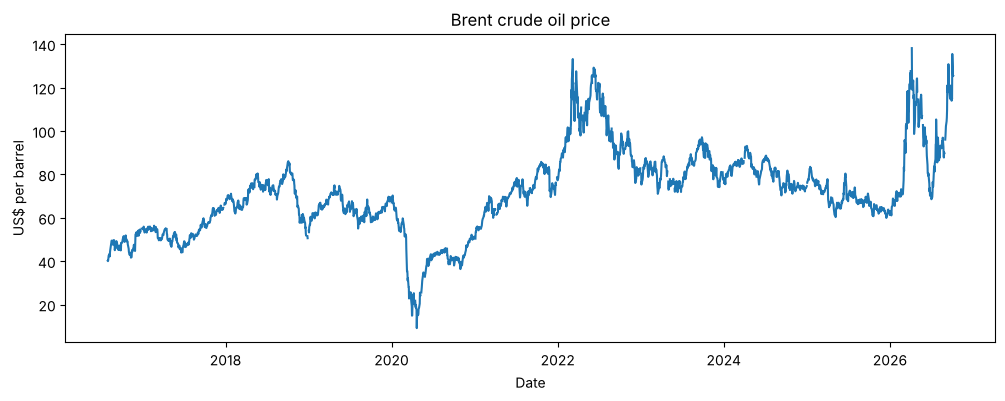

In [18]:
plt.figure(figsize=(12,4))
plt.plot(brent["date"], brent["brent_usd"])
plt.title("Brent crude oil price")
plt.xlabel("Date"); plt.ylabel("US$ per barrel")
plt.show()

## 5. Fuel excise
Excise only changes a few times a year, so there's no file to download. We type the rates in as a small table from the ATO's fuel tax credit rate pages. Each row says **"from this date, the rate is X cents per litre"**.

Notes:
- The ATO rates **exclude GST**. GST (10%) is also charged *on top of* excise, so at the pump excise adds `rate × 1.1`. We keep the raw rate here.
- The two values marked `# check` couldn't be confirmed online, so verify them on the ATO pages.
- The 2019–2020 changes happened in the first week of February/August; a few days' difference doesn't matter for a daily model.

In [19]:
excise = pd.DataFrame([
    ("2016-08-01", 39.6),   # check
    ("2017-02-01", 40.1),
    ("2017-08-01", 40.3),
    ("2018-02-05", 40.9),
    ("2018-08-01", 41.2),   # check
    ("2019-02-04", 41.6),
    ("2019-08-05", 41.8),
    ("2020-02-03", 42.3),
    ("2021-02-01", 42.7),   # no increase in Aug 2020 (inflation was negative)
    ("2021-08-02", 43.3),
    ("2022-02-01", 44.2),
    ("2022-03-30", 22.1),   # 2022 cut: excise halved
    ("2022-08-01", 23.0),
    ("2022-09-29", 46.0),   # cut ends
    ("2023-02-01", 47.7),
    ("2023-08-01", 48.8),
    ("2024-02-05", 49.6),
    ("2024-08-05", 50.6),
    ("2025-02-03", 50.8),
    ("2025-08-04", 51.6),
    ("2026-02-02", 52.6),
    ("2026-04-01", 20.6),   # 2026 cut: 60.9% reduction
    ("2026-07-01", 36.6),   # partly restored (30.4% reduction)
    ("2026-08-03", 53.7),   # back to full rate
], columns=["date", "excise"])

excise["date"] = pd.to_datetime(excise["date"])
excise

,date,excise
0,2016-08-01,39.6
1,2017-02-01,40.1
2,2017-08-01,40.3
3,2018-02-05,40.9
4,2018-08-01,41.2
5,2019-02-04,41.6
6,2019-08-05,41.8
7,2020-02-03,42.3
8,2021-02-01,42.7
9,2021-08-02,43.3


## 6. Merge everything into one daily table
FuelCheck prices change **every day, including weekends**, so the final table needs one row for **every calendar day**.

How we build it:
1. Make a list of every date from START to END (`pd.date_range`).
2. **Left-merge** each dataset onto it. "Left" means: keep every calendar day, and fill in a value where that dataset has one. Weekends and holidays end up empty (NaN).
3. **Forward fill** (`ffill`): an empty day takes the most recent known value. This is realistic because on a Saturday the latest wholesale price anyone knows is Friday's.
   - `limit=5` means we never carry a value more than 5 days. Weekends plus a public holiday is at most 4, so a longer gap would mean a real problem that we'd want to see, not hide.
4. Excise is different: it's a **step** that stays the same until the next change, so it's forward-filled with no limit.

In [20]:
daily = pd.DataFrame({"date": pd.date_range(START, END, freq="D")})
print("Calendar days:", len(daily))

daily = daily.merge(terminal_prices,   on="date", how="left")
daily = daily.merge(fx,    on="date", how="left")
daily = daily.merge(brent, on="date", how="left")
daily = daily.merge(excise, on="date", how="left")

print("Missing BEFORE filling:\n", daily.isna().sum())

Calendar days: 3722
Missing BEFORE filling:
 date                 0
terminal_price    1062
audusd            1163
brent_usd         1138
excise            3698
dtype: int64


In [21]:
daily[["terminal_price", "audusd", "brent_usd"]] = daily[["terminal_price", "audusd", "brent_usd"]].ffill(limit=5)
daily["excise"] = daily["excise"].ffill()          # step function: holds until the next change

# The very first day (1 Aug 2016) was a NSW bank holiday, so the RBA has no rate and there's no earlier day
# to copy from. bfill (backward fill) takes the NEXT day's value instead, for that one row only.
daily["audusd"] = daily["audusd"].bfill(limit=1)

print("Missing AFTER filling:\n", daily.isna().sum())
daily.head(10)

Missing AFTER filling:
 date              0
terminal_price    0
audusd            0
brent_usd         0
excise            0
dtype: int64


,date,terminal_price,audusd,brent_usd,excise
0,2016-08-01,100.9,0.7547,40.17,39.6
1,2016-08-02,99.8,0.7547,40.00,39.6
2,2016-08-03,99.7,0.7589,40.45,39.6
3,2016-08-04,99.2,0.7607,41.33,39.6
4,2016-08-05,98.6,0.7660,42.47,39.6
5,2016-08-06,98.6,0.7660,42.47,39.6
6,2016-08-07,98.6,0.7660,42.47,39.6
7,2016-08-08,98.3,0.7610,43.24,39.6
8,2016-08-09,98.4,0.7631,43.37,39.6
9,2016-08-10,98.7,0.7695,42.19,39.6


## 7. Put oil in the same units as the pump price
Brent is in **US dollars per barrel**, but pump prices are in **Australian cents per litre**. To compare them directly we convert:

$$\text{Brent (A¢/L)} = \frac{\text{Brent (US\$/bbl)}}{\text{AUD/USD}} \times \frac{100}{158.987}$$

- dividing by AUD/USD converts US$ to A$ (e.g. US$80 ÷ 0.65 = A$123)
- one barrel = **158.987 litres**, and × 100 turns dollars into cents

This one column captures **both** oil and the exchange rate, which is exactly how they affect Australian fuel.

In [22]:
daily["brent_aud_cpl"] = daily["brent_usd"] / daily["audusd"] * 100 / 158.987
daily[["date", "brent_usd", "audusd", "brent_aud_cpl"]].tail()

,date,brent_usd,audusd,brent_aud_cpl
3717,2026-10-05,125.51,0.6933,113.866380
3718,2026-10-06,125.44,0.6970,113.198756
3719,2026-10-07,125.44,0.6970,113.198756
3720,2026-10-08,125.44,0.6956,113.426585
3721,2026-10-09,125.44,0.6979,113.052776


### Check: does the TGP make sense?
The TGP should roughly equal **crude oil cost + refining/shipping + excise + GST**. So if we take the TGP, remove GST (÷ 1.1) and subtract excise, what's left should follow Brent closely. If it does, all four datasets are lined up correctly.

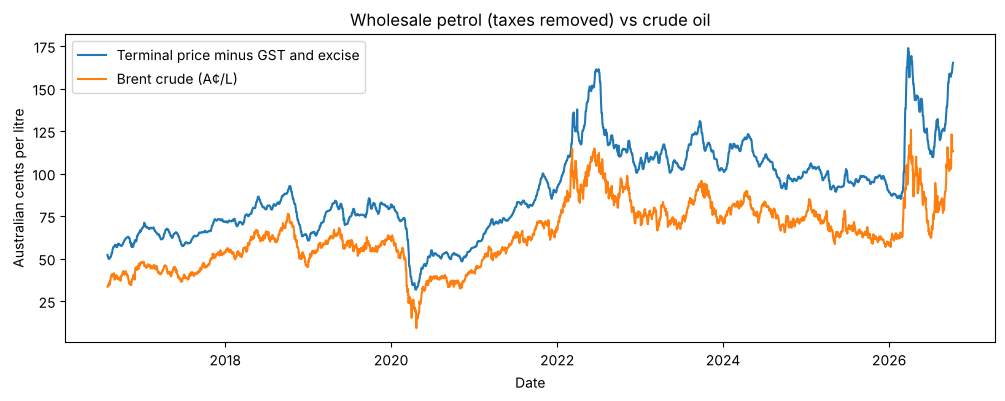

In [23]:
daily["terminal_price_ex_tax"] = daily["terminal_price"] / 1.1 - daily["excise"]

plt.figure(figsize=(12,4))
plt.plot(daily["date"], daily["terminal_price_ex_tax"], label="Terminal price minus GST and excise")
plt.plot(daily["date"], daily["brent_aud_cpl"], label="Brent crude (A¢/L)")
plt.title("Wholesale petrol (taxes removed) vs crude oil")
plt.xlabel("Date"); plt.ylabel("Australian cents per litre")
plt.legend(); plt.show()

The two lines should move together, with a fairly steady gap between them (refining, shipping and wholesale margin). If the excise table were wrong, you'd see **sudden jumps** in the blue line on the excise change dates, e.g. in March 2022 or April 2026. A smooth blue line through those dates means the excise table is right.

In [24]:
# Correlation between the drivers (1 = move perfectly together)
daily[["terminal_price", "brent_usd", "audusd", "brent_aud_cpl", "excise"]].corr().round(2)

,terminal_price,brent_usd,audusd,brent_aud_cpl,excise
terminal_price,1.00,0.87,-0.52,0.93,0.21
brent_usd,0.87,1.00,-0.20,0.98,-0.16
audusd,-0.52,-0.20,1.00,-0.39,-0.39
brent_aud_cpl,0.93,0.98,-0.39,1.00,-0.06
excise,0.21,-0.16,-0.39,-0.06,1.00


In [25]:
print(daily.shape)
daily.describe().round(2)

(3722, 7)


,date,terminal_price,audusd,brent_usd,excise,brent_aud_cpl,terminal_price_ex_tax
count,3722,3722.00,3722.00,3722.00,3722.00,3722.00,3722.00
mean,2021-09-04 12:00:00,145.44,0.70,71.46,43.03,64.32,89.19
min,2016-08-01 00:00:00,81.40,0.56,9.12,20.60,9.09,31.70
25%,2019-02-17 06:00:00,122.20,0.67,60.17,40.90,52.15,69.83
50%,2021-09-04 12:00:00,142.20,0.70,71.02,42.30,63.32,86.45
75%,2024-03-22 18:00:00,167.40,0.74,82.15,48.80,76.27,106.85
max,2026-10-09 00:00:00,249.00,0.81,138.21,53.70,125.70,173.76
std,NaN,29.18,0.05,19.44,7.32,18.66,25.96


### End of Part 1
`daily` now holds one clean row per day from August 2016 to October 2026: TGP, AUD/USD, Brent (US$ and A¢/L) and excise.

**Next (Part 2):** load the FuelCheck files, filter to Parramatta U91, turn price *changes* into a daily average price, and merge it onto `daily`.